In [6]:
%pip install -q pandas numpy matplotlib jinja2


Note: you may need to restart the kernel to use updated packages.


# Complete Model Comparison Notebook
## Classification, Regression, and Clustering

This notebook puts each model-comparison metric in its own graph. For example, all classification accuracy values appear in one graph, all weighted F1-scores appear in another, and so on.

The values below are taken from the saved outputs of the project's original notebooks. The notebook **visualises those recorded results; it does not retrain models**.

---

### How to use
1. Open this file in **Jupyter Notebook** or **VS Code**.
2. Run all cells from top to bottom.
3. Read the explanation under each graph for your report or presentation.

---

> **Direction reminder:** accuracy, precision, recall, F1, ROC-AUC, R², silhouette and Calinski–Harabasz are generally **better when higher**. RMSE, MAE, Davies–Bouldin and fitting time are **better when lower**.

---
## Part 1 — Classification

The classification model predicts one of **five civil-case outcomes**. Each graph below compares the same metric across all **11 baseline classifiers**.

### Classification results table

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Global style ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "#f8f9fa",
    "axes.facecolor":   "#ffffff",
    "axes.spines.top":  False,
    "axes.spines.right":False,
    "axes.titlesize":   14,
    "axes.titleweight": "bold",
    "axes.labelsize":   11,
    "xtick.labelsize":  9,
    "ytick.labelsize":  9,
    "font.family":      "DejaVu Sans",
})

# ── Colour palettes ──────────────────────────────────────────────────────────
CLF_COLOUR   = "#4C72B0"   # classification bars
REG_COLOUR   = "#55A868"   # regression bars
CLUST_COLOUR = "#C44E52"   # clustering bars
LINE_COLOUR  = "#DD8452"   # line-chart colour

In [8]:
classification = pd.DataFrame({
    "Model": [
        "MLP Classifier", "Bagging Classifier", "Random Forest Classifier",
        "Gradient Boosting Classifier", "Decision Tree Classifier",
        "KNN Classifier", "SVC", "Naive Bayes (Gaussian)",
        "AdaBoost Classifier", "Logistic Regression",
        "Single-Layer Perceptron"
    ],
    "Accuracy":          [0.6633, 0.6329, 0.6164, 0.6255, 0.5445,
                          0.5711, 0.5240, 0.5017, 0.5449, 0.4425, 0.4450],
    "Precision":         [0.6639, 0.6721, 0.6735, 0.6365, 0.6202,
                          0.5599, 0.6067, 0.5067, 0.5113, 0.5654, 0.4284],
    "Recall":            [0.6633, 0.6329, 0.6164, 0.6255, 0.5445,
                          0.5711, 0.5240, 0.5017, 0.5449, 0.4425, 0.4450],
    "Weighted F1":       [0.6514, 0.6409, 0.6263, 0.6051, 0.5624,
                          0.5580, 0.5370, 0.4997, 0.4980, 0.4637, 0.4234],
    "ROC-AUC":           [0.8544, 0.8546, 0.8577, 0.8262, 0.8021,
                          0.7630, 0.7995, 0.7189, 0.7462, 0.7576, 0.6267],
    "Fit time (seconds)":[111.3340, 168.7640, 23.6929, 1888.2846, 68.7201,
                          0.2839, 194.8054, 2.6170, 167.9221, 11.3237, 2.3273]
})

classification.style \
    .set_caption("Classification Baseline Results") \
    .format({
        "Accuracy": "{:.4f}", "Precision": "{:.4f}",
        "Recall":   "{:.4f}", "Weighted F1": "{:.4f}",
        "ROC-AUC":  "{:.4f}", "Fit time (seconds)": "{:.4f}"
    }) \
    .background_gradient(subset=["Accuracy","Weighted F1","ROC-AUC"], cmap="Blues") \
    .highlight_min(subset=["Fit time (seconds)"], color="#d4f1d4") \
    .set_properties(**{"text-align": "center"})

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC,Fit time (seconds)
0,MLP Classifier,0.6633,0.6639,0.6633,0.6514,0.8544,111.3340
1,Bagging Classifier,0.6329,0.6721,0.6329,0.6409,0.8546,168.7640
2,Random Forest Classifier,0.6164,0.6735,0.6164,0.6263,0.8577,23.6929
3,Gradient Boosting Classifier,0.6255,0.6365,0.6255,0.6051,0.8262,1888.2846
4,Decision Tree Classifier,0.5445,0.6202,0.5445,0.5624,0.8021,68.7201
5,KNN Classifier,0.5711,0.5599,0.5711,0.5580,0.7630,0.2839
6,SVC,0.5240,0.6067,0.5240,0.5370,0.7995,194.8054
7,Naive Bayes (Gaussian),0.5017,0.5067,0.5017,0.4997,0.7189,2.6170
8,AdaBoost Classifier,0.5449,0.5113,0.5449,0.4980,0.7462,167.9221
9,Logistic Regression,0.4425,0.5654,0.4425,0.4637,0.7576,11.3237


---
### 1.1 Classification accuracy — all models

**What it means:** Accuracy is the fraction of test cases whose predicted outcome matches the actual outcome. **Higher is better.**

**How to explain it:** MLP has the highest recorded baseline accuracy at approximately **66.33%**. That means it correctly classifies around 66 out of every 100 test cases overall. It does *not* mean the model is equally accurate for every outcome class.

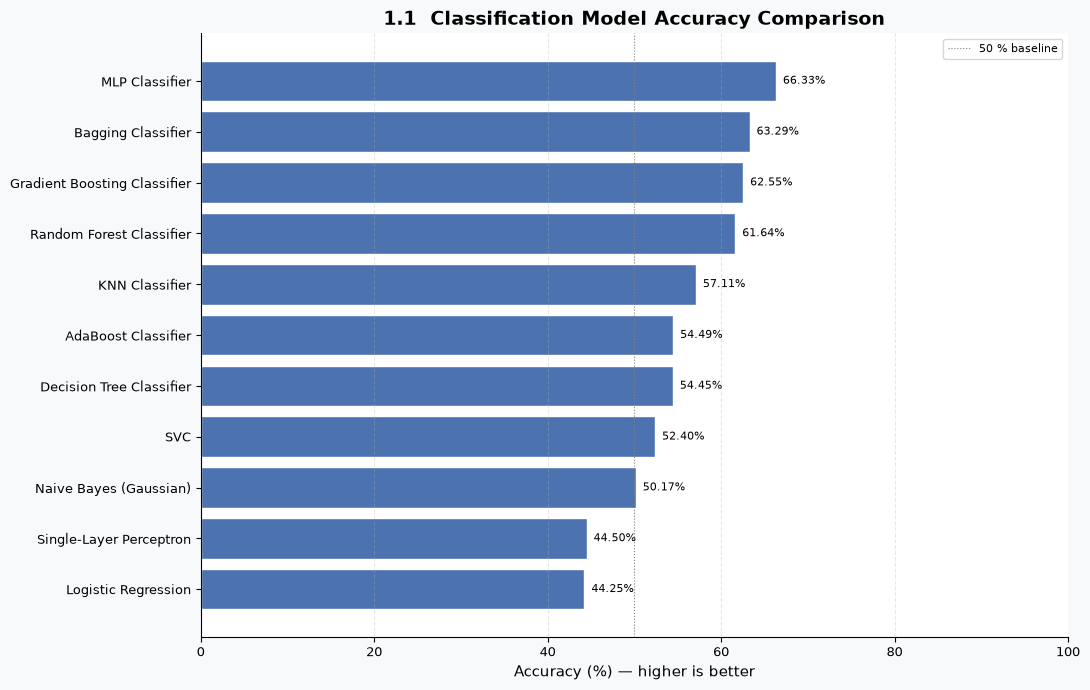

In [9]:
plot_df = classification.sort_values("Accuracy")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["Accuracy"] * 100, color=CLF_COLOUR, edgecolor="white")
ax.set_xlabel("Accuracy (%) — higher is better")
ax.set_title("1.1  Classification Model Accuracy Comparison")
ax.set_xlim(0, 100)
ax.axvline(50, color="grey", linestyle=":", linewidth=0.8, label="50 % baseline")
ax.legend(fontsize=8)
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["Accuracy"] * 100):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2,
            f"{v:.2f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 1.2 Classification precision — all models

**What it means:** Precision asks: when a model predicts a particular outcome, how often is that prediction correct? These are **weighted** precision values across the outcome classes. **Higher is better.**

**How to explain it:** Random Forest has the highest recorded weighted precision (about **67.35%**), followed closely by Bagging (67.21%). A model can have higher precision but lower recall, so this graph should be read together with the recall and F1 graphs.

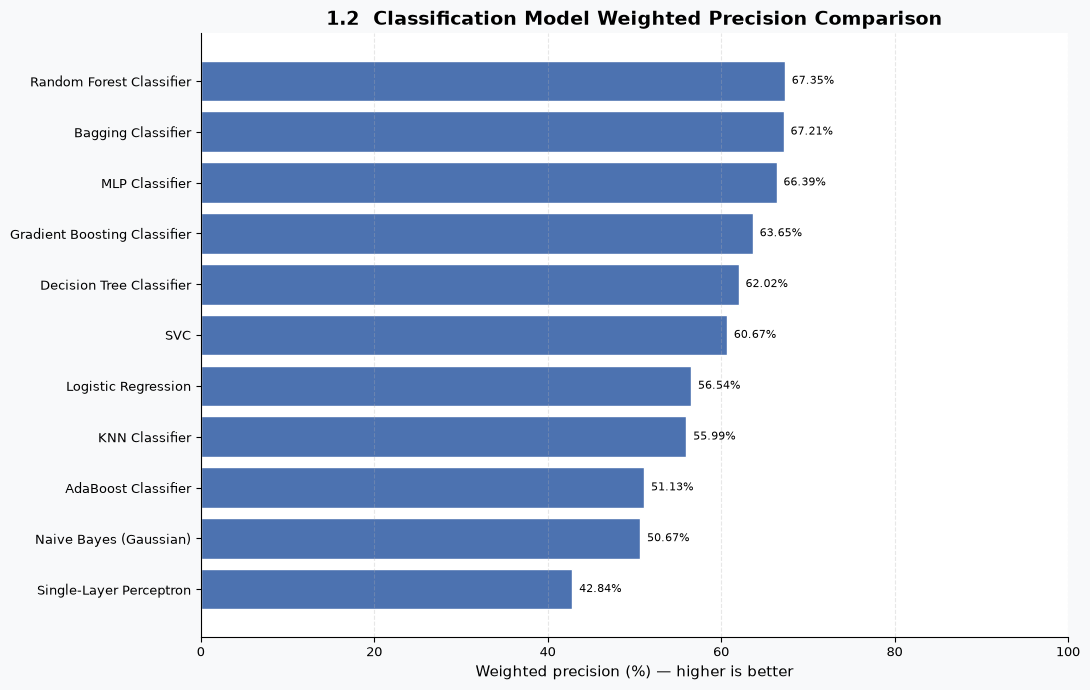

In [10]:
plot_df = classification.sort_values("Precision")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["Precision"] * 100, color=CLF_COLOUR, edgecolor="white")
ax.set_xlabel("Weighted precision (%) — higher is better")
ax.set_title("1.2  Classification Model Weighted Precision Comparison")
ax.set_xlim(0, 100)
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["Precision"] * 100):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2,
            f"{v:.2f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 1.3 Classification recall — all models

**What it means:** Recall asks: out of all cases that truly belong to an outcome class, how many did the model correctly identify? These are **weighted** recall values. **Higher is better.**

> **Important observation:** In single-label multiclass classification, weighted recall equals accuracy. That is why the bars and values in this graph match the accuracy graph. This is expected, not a plotting error.

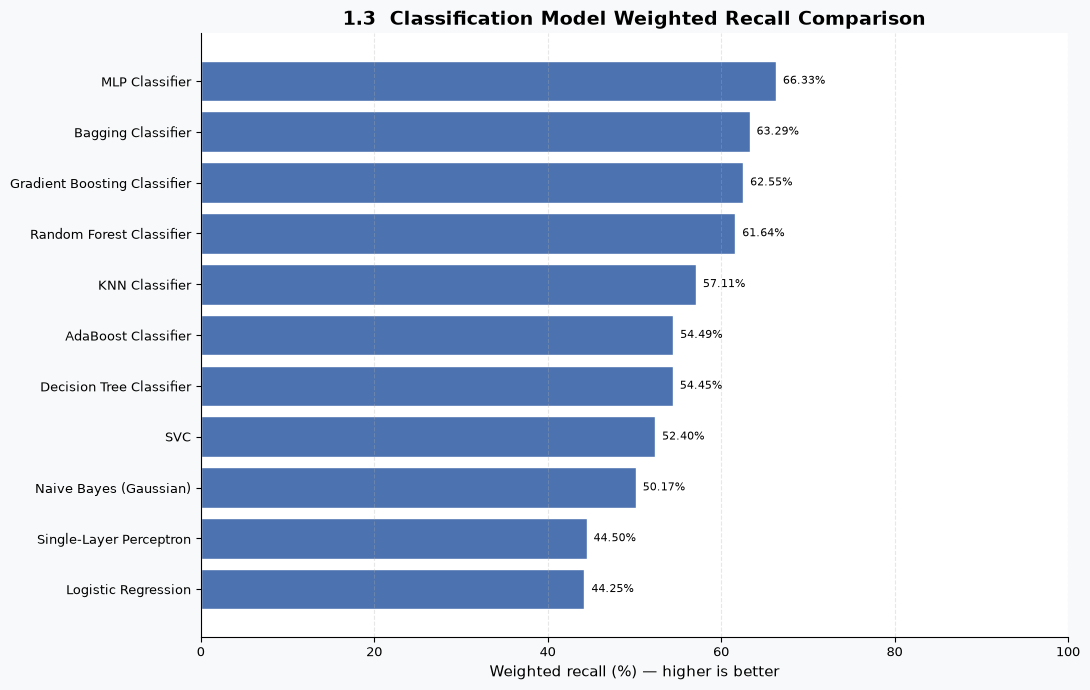

In [11]:
plot_df = classification.sort_values("Recall")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["Recall"] * 100, color=CLF_COLOUR, edgecolor="white")
ax.set_xlabel("Weighted recall (%) — higher is better")
ax.set_title("1.3  Classification Model Weighted Recall Comparison")
ax.set_xlim(0, 100)
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["Recall"] * 100):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2,
            f"{v:.2f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 1.4 Weighted F1-score — all models

**What it means:** Weighted F1 combines precision and recall into one score, taking the number of examples in each class into account. **Higher is better.**

**How to explain it:** MLP ranks first with a weighted F1-score of approximately **65.14%**, followed by Bagging at 64.09% and Random Forest at 62.63%. This is a useful headline graph because the dataset has outcome classes of different sizes.

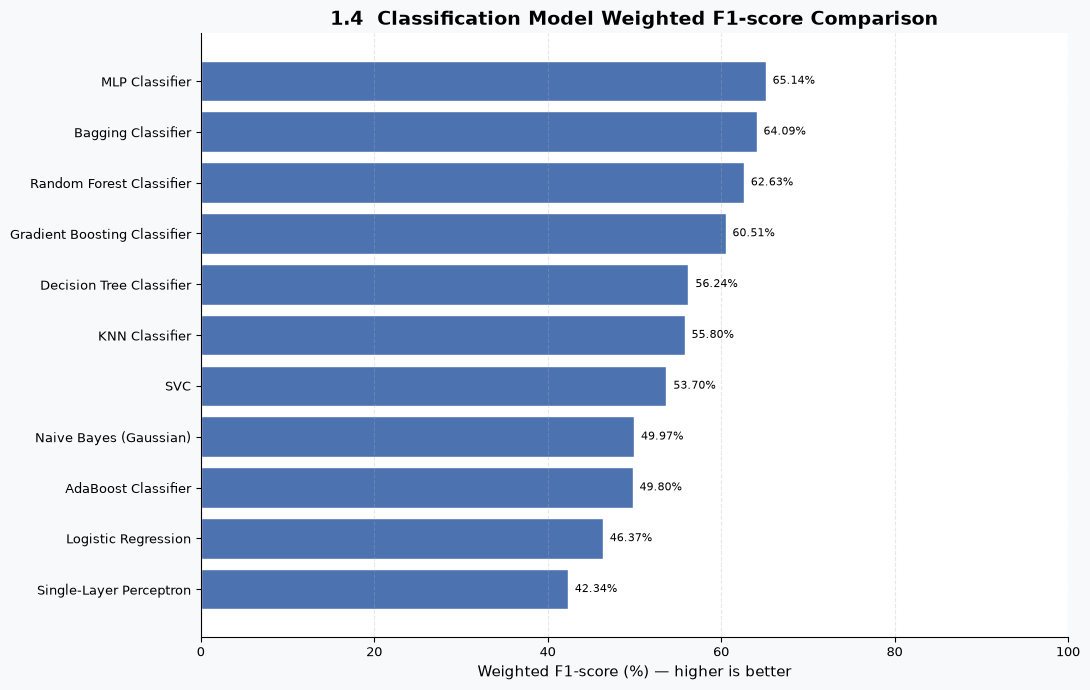

In [12]:
plot_df = classification.sort_values("Weighted F1")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["Weighted F1"] * 100, color=CLF_COLOUR, edgecolor="white")
ax.set_xlabel("Weighted F1-score (%) — higher is better")
ax.set_title("1.4  Classification Model Weighted F1-score Comparison")
ax.set_xlim(0, 100)
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["Weighted F1"] * 100):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2,
            f"{v:.2f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 1.5 ROC-AUC — all models

**What it means:** ROC-AUC measures how well prediction scores distinguish each outcome class from the other classes using a one-vs-rest approach. **Higher is better.**

**How to explain it:** Random Forest has the highest recorded ROC-AUC at **0.8577**. MLP and Bagging are close behind. ROC-AUC evaluates ranking/discrimination, so the best model by ROC-AUC does not have to be the best by accuracy or F1.

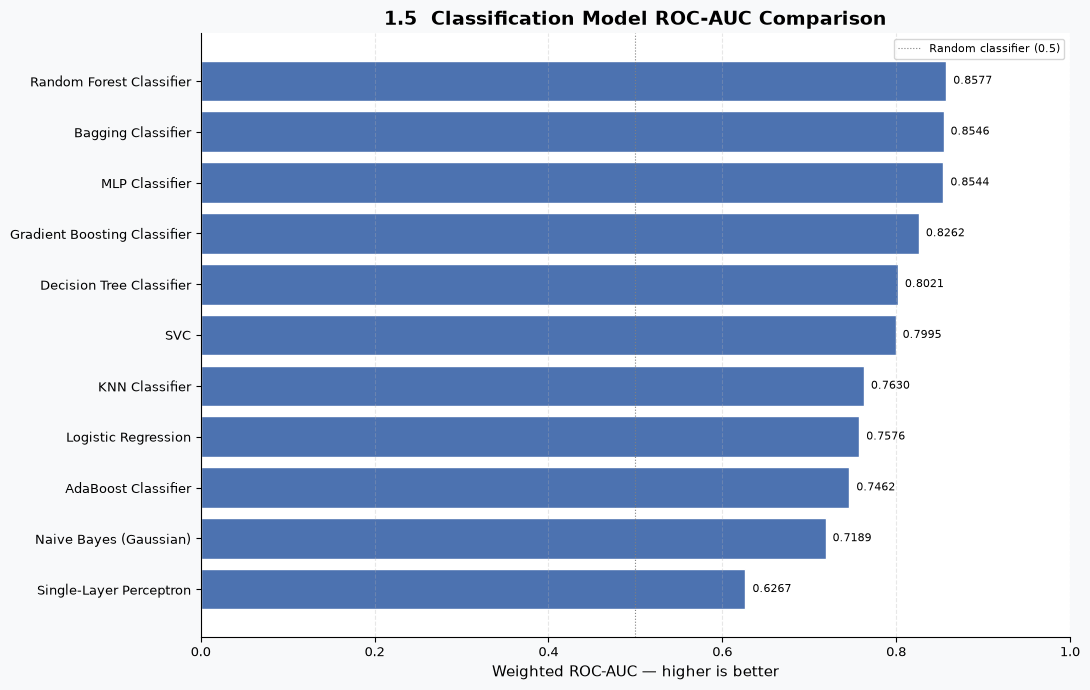

In [13]:
plot_df = classification.sort_values("ROC-AUC")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["ROC-AUC"], color=CLF_COLOUR, edgecolor="white")
ax.set_xlabel("Weighted ROC-AUC — higher is better")
ax.set_title("1.5  Classification Model ROC-AUC Comparison")
ax.set_xlim(0, 1)
ax.axvline(0.5, color="grey", linestyle=":", linewidth=0.8, label="Random classifier (0.5)")
ax.legend(fontsize=8)
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["ROC-AUC"]):
    ax.text(v + 0.008, b.get_y() + b.get_height() / 2,
            f"{v:.4f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 1.6 Classification model fitting time — all models

**What it means:** Fitting time is how long the model took to train in the recorded run. **Lower is faster.** It is a speed measure, not a prediction-quality measure.

**How to explain it:** Gradient Boosting took the longest in the recorded run. KNN and the Single-Layer Perceptron had very short recorded fit times. Training time depends on hardware, data, parameters and the run environment, so it should not be treated as a permanent benchmark.

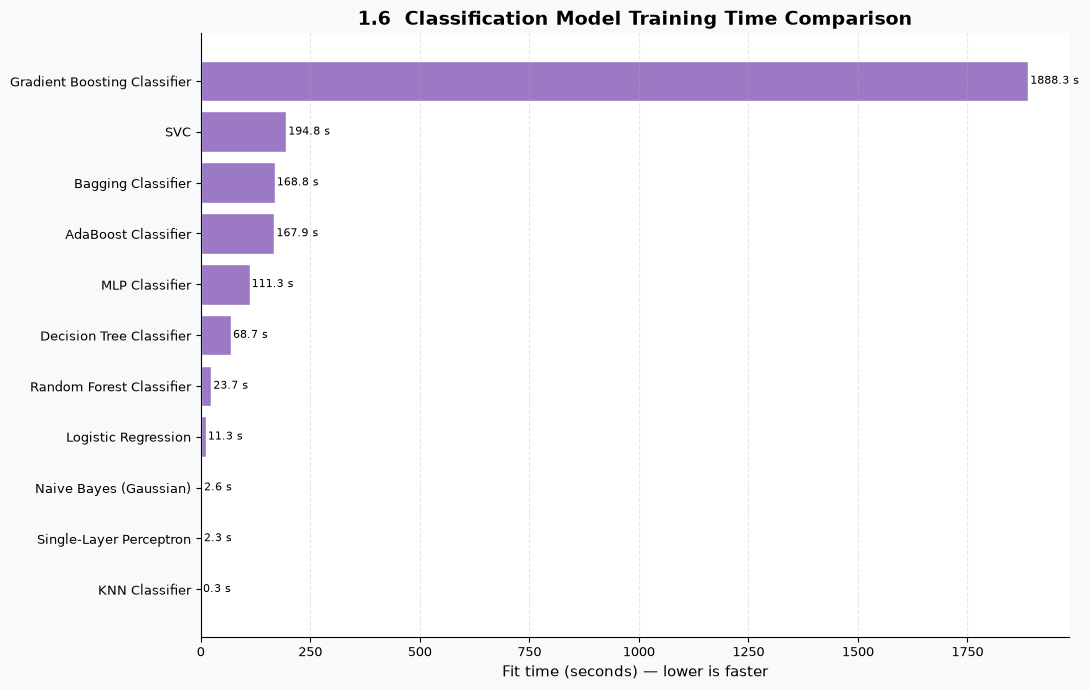

In [14]:
plot_df = classification.sort_values("Fit time (seconds)")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["Fit time (seconds)"],
               color="#9b79c4", edgecolor="white")
ax.set_xlabel("Fit time (seconds) — lower is faster")
ax.set_title("1.6  Classification Model Training Time Comparison")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["Fit time (seconds)"]):
    ax.text(v + 5, b.get_y() + b.get_height() / 2,
            f"{v:.1f} s", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 1.7 Baseline versus tuned classification models

The original notebook tuned **Bagging** and **MLP**. This section shows accuracy in one graph and weighted F1 in another graph, so each metric is compared like-for-like.

Recorded results:
- **Bagging:** accuracy 63.29% → 63.18%; weighted F1 64.09% → 63.92%.
- **MLP:** accuracy 66.33% → 66.54%; weighted F1 65.14% → 65.23%.

Tuning **slightly improved MLP**, while Bagging **decreased slightly** on these test metrics.

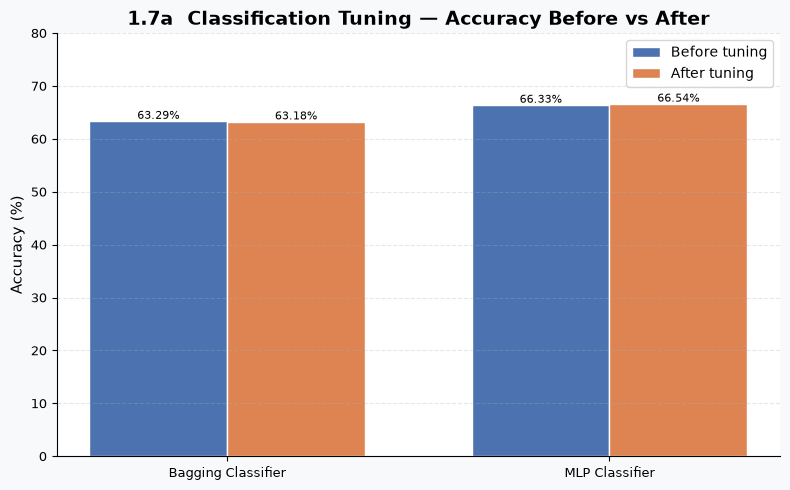

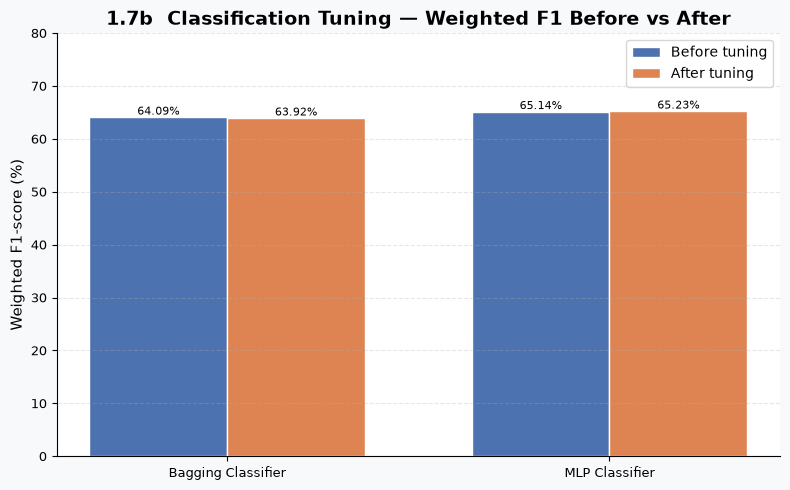

In [15]:
tuning_clf = pd.DataFrame({
    "Model":           ["Bagging Classifier", "MLP Classifier"],
    "Accuracy before": [0.6329, 0.6633],
    "Accuracy after":  [0.6318, 0.6654],
    "F1 before":       [0.6409, 0.6514],
    "F1 after":        [0.6392, 0.6523]
})

x = np.arange(len(tuning_clf))
w = 0.36

# ── Accuracy ─────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w / 2, tuning_clf["Accuracy before"] * 100, w,
            label="Before tuning", color="#4C72B0", edgecolor="white")
b2 = ax.bar(x + w / 2, tuning_clf["Accuracy after"] * 100, w,
            label="After tuning",  color="#DD8452", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(tuning_clf["Model"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("1.7a  Classification Tuning — Accuracy Before vs After")
ax.set_ylim(0, 80)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
for b, v in list(zip(b1, tuning_clf["Accuracy before"] * 100)) + \
            list(zip(b2, tuning_clf["Accuracy after"] * 100)):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5,
            f"{v:.2f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

# ── Weighted F1 ──────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w / 2, tuning_clf["F1 before"] * 100, w,
            label="Before tuning", color="#4C72B0", edgecolor="white")
b2 = ax.bar(x + w / 2, tuning_clf["F1 after"] * 100, w,
            label="After tuning",  color="#DD8452", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(tuning_clf["Model"])
ax.set_ylabel("Weighted F1-score (%)")
ax.set_title("1.7b  Classification Tuning — Weighted F1 Before vs After")
ax.set_ylim(0, 80)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
for b, v in list(zip(b1, tuning_clf["F1 before"] * 100)) + \
            list(zip(b2, tuning_clf["F1 after"] * 100)):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5,
            f"{v:.2f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### Classification summary

| Metric | Best model | Value |
|--------|-----------|-------|
| Baseline accuracy | **MLP Classifier** | 66.33% |
| Weighted F1 | **MLP Classifier** | 65.14% |
| Weighted precision | **Random Forest Classifier** | 67.35% |
| ROC-AUC | **Random Forest Classifier** | 0.8577 |

**Tuning:** MLP improved slightly; Bagging decreased slightly on the recorded test scores.

> No single metric tells the whole story. State which metric you are using when saying a model is “best.”

---
## Part 2 — Regression

Regression predicts **how many days** a civil case takes to reach termination. Each graph below compares one metric across all **ten baseline regression models**.

- **R²:** higher is better; measures variation explained relative to predicting the mean.
- **RMSE:** lower is better; error in days, with larger errors penalised more strongly.
- **MAE:** lower is better; average absolute error in days.
- **Fit time:** lower is faster; not a prediction-quality measure.

In [16]:
regression = pd.DataFrame({
    "Model": [
        "Linear Regression", "Ridge Regression", "Lasso Regression",
        "ElasticNet Regression", "Polynomial Regression",
        "Decision Tree Regressor", "Random Forest Regressor",
        "Gradient Boosting Regressor", "SVR", "KNN Regressor"
    ],
    "R²":              [0.1913, 0.1913, 0.1900, 0.1058, 0.3646,
                        0.3537, 0.4392, 0.3391, 0.0022, 0.2728],
    "RMSE (days)":     [383.3251, 383.3250, 383.6268, 403.0801, 339.7945,
                        342.6946, 319.2200, 346.5292, 425.7909, 363.5034],
    "MAE (days)":      [267.3819, 267.3819, 267.9281, 291.0613, 234.2331,
                        228.5855, 212.4399, 238.9321, 261.4313, 244.3511],
    "Fit time (seconds)":[0.2761, 0.0974, 0.0920, 0.0975, 0.0000,
                          6.7879, 56.0398, 260.3553, 65.8468, 0.6640]
})

regression.style \
    .set_caption("Regression Baseline Results") \
    .format({
        "R²": "{:.4f}",
        "RMSE (days)": "{:.4f}",
        "MAE (days)": "{:.4f}",
        "Fit time (seconds)": "{:.4f}"
    }) \
    .background_gradient(subset=["R²"], cmap="Greens") \
    .background_gradient(subset=["RMSE (days)","MAE (days)"], cmap="Reds_r") \
    .set_properties(**{"text-align": "center"})

,Model,R²,RMSE (days),MAE (days),Fit time (seconds)
0,Linear Regression,0.1913,383.3251,267.3819,0.2761
1,Ridge Regression,0.1913,383.3250,267.3819,0.0974
2,Lasso Regression,0.1900,383.6268,267.9281,0.0920
3,ElasticNet Regression,0.1058,403.0801,291.0613,0.0975
4,Polynomial Regression,0.3646,339.7945,234.2331,0.0000
5,Decision Tree Regressor,0.3537,342.6946,228.5855,6.7879
6,Random Forest Regressor,0.4392,319.2200,212.4399,56.0398
7,Gradient Boosting Regressor,0.3391,346.5292,238.9321,260.3553
8,SVR,0.0022,425.7909,261.4313,65.8468
9,KNN Regressor,0.2728,363.5034,244.3511,0.6640


---
### 2.1 Regression R² — all models

**What it means:** R² describes how much variation in case duration the model explains relative to a mean-duration baseline. **Higher is better.**

**How to explain it:** Random Forest has the highest baseline R² (**0.4392**), followed by Polynomial Regression (0.3646). SVR's R² is close to zero, meaning it explains little more variation than the mean baseline on this test set.

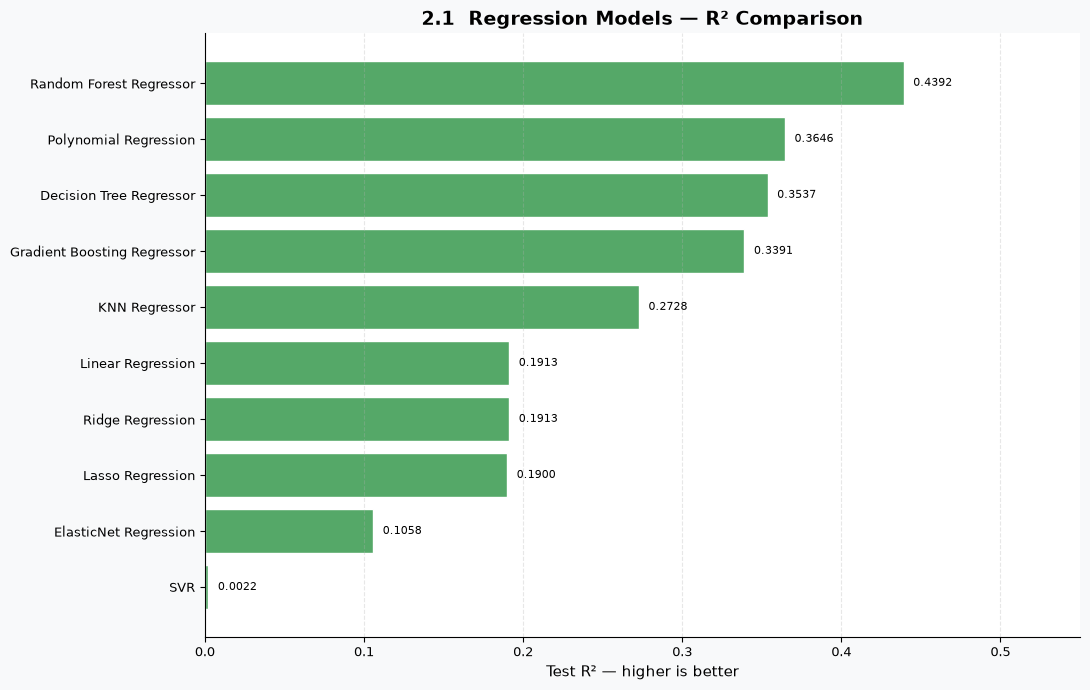

In [17]:
plot_df = regression.sort_values("R²")
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["R²"], color=REG_COLOUR, edgecolor="white")
ax.set_xlabel("Test R² — higher is better")
ax.set_title("2.1  Regression Models — R² Comparison")
ax.set_xlim(0, 0.55)
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["R²"]):
    ax.text(v + 0.006, b.get_y() + b.get_height() / 2,
            f"{v:.4f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 2.2 Regression RMSE — all models

**What it means:** RMSE is an error measure in days. **Lower is better**, and large errors affect it more strongly than smaller errors.

**How to explain it:** Random Forest has the lowest baseline RMSE at approximately **319.22 days**. SVR has the highest at approximately 425.79 days. An RMSE of 319 days does not mean every prediction is off by 319 days; it summarises errors across the test set.

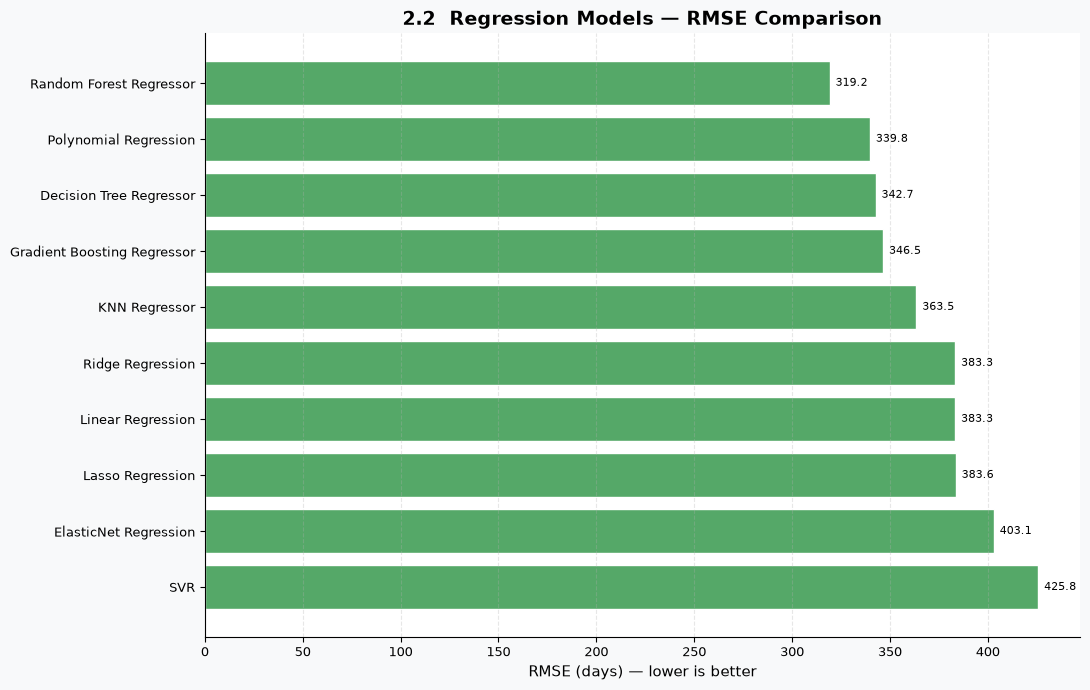

In [18]:
plot_df = regression.sort_values("RMSE (days)", ascending=False)
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["RMSE (days)"], color=REG_COLOUR, edgecolor="white")
ax.set_xlabel("RMSE (days) — lower is better")
ax.set_title("2.2  Regression Models — RMSE Comparison")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["RMSE (days)"]):
    ax.text(v + 3, b.get_y() + b.get_height() / 2,
            f"{v:.1f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 2.3 Regression MAE — all models

**What it means:** MAE is the average absolute difference between the actual duration and the predicted duration, measured in days. **Lower is better.**

**How to explain it:** Random Forest has the lowest baseline MAE (about **212.44 days**). This is the average absolute prediction error across the test observations, not the error for every individual case.

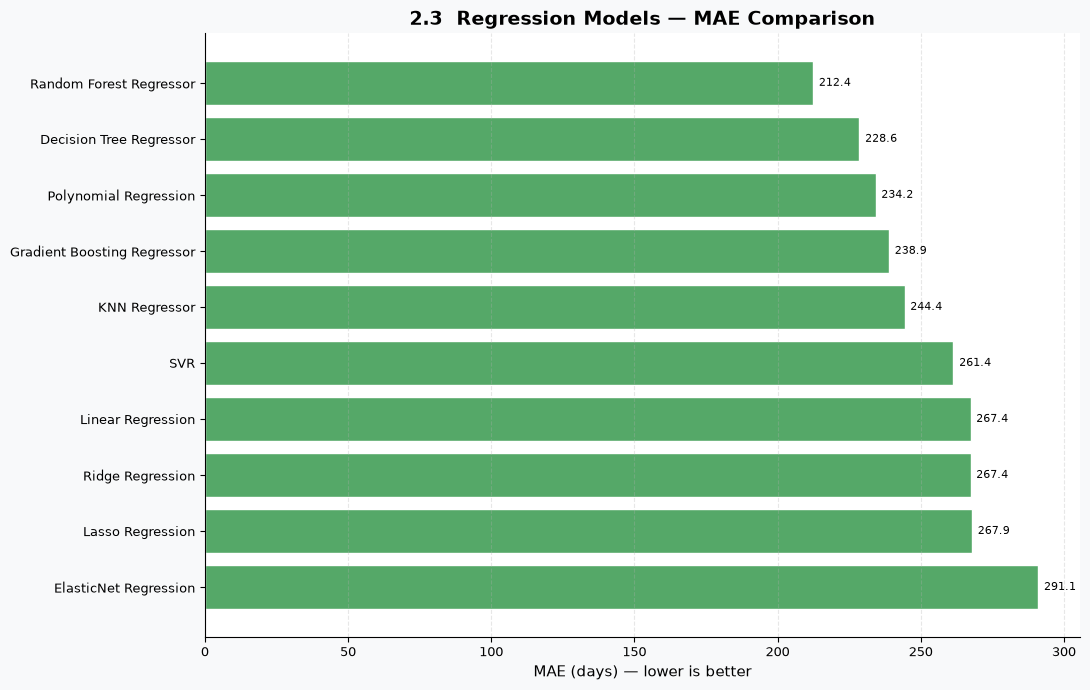

In [19]:
plot_df = regression.sort_values("MAE (days)", ascending=False)
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_df["Model"], plot_df["MAE (days)"], color=REG_COLOUR, edgecolor="white")
ax.set_xlabel("MAE (days) — lower is better")
ax.set_title("2.3  Regression Models — MAE Comparison")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(bars, plot_df["MAE (days)"]):
    ax.text(v + 2, b.get_y() + b.get_height() / 2,
            f"{v:.1f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 2.4 Regression fitting time — all models

**What it means:** This compares the recorded model-fitting times. **Lower is faster.** The recorded zero for Polynomial Regression reflects how timing was logged in that notebook and should not be interpreted as proof that polynomial regression always takes no time.

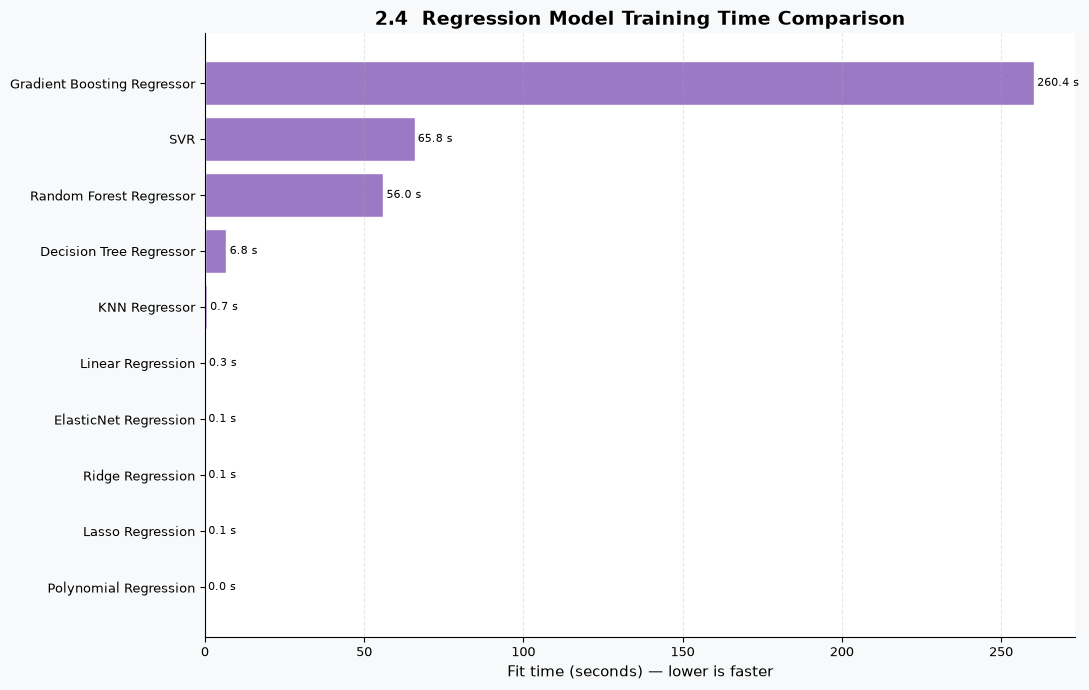

In [20]:
plot_df = regression.sort_values("Fit time (seconds)")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(plot_df["Model"], plot_df["Fit time (seconds)"],
        color="#9b79c4", edgecolor="white")
ax.set_xlabel("Fit time (seconds) — lower is faster")
ax.set_title("2.4  Regression Model Training Time Comparison")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for b, v in zip(ax.patches, plot_df["Fit time (seconds)"]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2,
            f"{v:.1f} s", va="center", fontsize=8)
plt.tight_layout()
plt.show()

---
### 2.5 Random Forest regression — before versus after tuning

**R² comparison:** baseline Random Forest R² = 0.4392; tuned Random Forest R² = 0.4529.  
The improvement is **0.0137 R² points (1.37 percentage points)**.  
This is a modest improvement, and it does not mean the model can predict every case duration accurately.

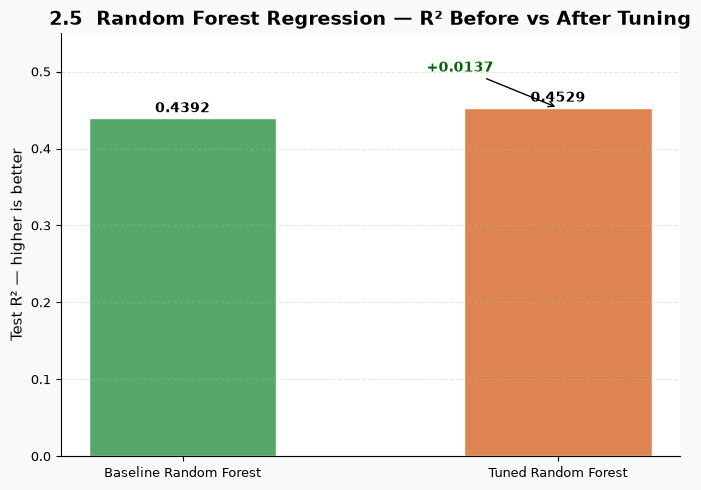

In [21]:
rf_tuning = pd.DataFrame({
    "Version":  ["Baseline Random Forest", "Tuned Random Forest"],
    "Test R²":  [0.4392, 0.4529]
})

fig, ax = plt.subplots(figsize=(7, 5))
colors = [REG_COLOUR, "#DD8452"]
bars = ax.bar(rf_tuning["Version"], rf_tuning["Test R²"], color=colors, edgecolor="white", width=0.5)
ax.set_ylim(0, 0.55)
ax.set_ylabel("Test R² — higher is better")
ax.set_title("2.5  Random Forest Regression — R² Before vs After Tuning")
ax.grid(axis="y", linestyle="--", alpha=0.3)
for b, v in zip(bars, rf_tuning["Test R²"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.008,
            f"{v:.4f}", ha="center", fontsize=10, fontweight="bold")
ax.annotate("+0.0137", xy=(1, 0.4529), xytext=(0.65, 0.50),
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=10, color="darkgreen", fontweight="bold")
plt.tight_layout()
plt.show()

---
### Regression summary

| Metric | Best baseline model | Value |
|--------|-------------------|-------|
| R² | **Random Forest Regressor** | 0.4392 |
| RMSE | **Random Forest Regressor** | 319.22 days |
| MAE | **Random Forest Regressor** | 212.44 days |

- **After tuning:** Random Forest R² increased to **0.4529**.
- The scores indicate that the model captures some patterns, but a substantial amount of case-duration variation remains unexplained.

---
## Part 3 — Clustering

Clustering groups similar cases **without training against a known target outcome**. The notebook has two distinct experiments:

1. A **fixed five-cluster comparison** of K-Means and Agglomerative Hierarchical Clustering.
2. A **K-Means experiment** comparing the number of clusters, *k* = 2 through *k* = 8.

> Keep these experiments **separate** when presenting results.

In [22]:
clustering = pd.DataFrame({
    "Algorithm": ["K-Means (5 clusters)", "Agglomerative Hierarchical (5 clusters)"],
    "Silhouette":         [0.184863, 0.209805],
    "Davies-Bouldin":     [1.563674, 1.587768],
    "Calinski-Harabasz":  [2511.508967, 2356.562759]
})

clustering.style \
    .set_caption("Five-Cluster Comparison Results") \
    .format({
        "Silhouette": "{:.6f}",
        "Davies-Bouldin": "{:.6f}",
        "Calinski-Harabasz": "{:.6f}"
    }) \
    .set_properties(**{"text-align": "center"})

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means (5 clusters),0.184863,1.563674,2511.508967
1,Agglomerative Hierarchical (5 clusters),0.209805,1.587768,2356.562759


---
### 3.1 Silhouette score — K-Means vs Agglomerative

**What it means:** Silhouette measures how similar each point is to its own cluster compared with other clusters. **Higher is better.**

**Interpretation:** Agglomerative has the higher recorded silhouette score (**0.2098** vs 0.1849), suggesting better average separation according to this metric. Both scores are relatively low, so clusters may overlap.

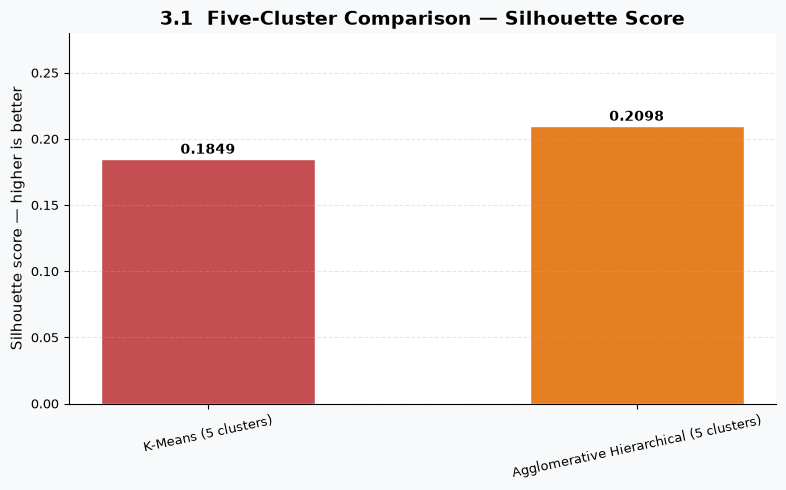

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(clustering["Algorithm"], clustering["Silhouette"],
              color=[CLUST_COLOUR, "#E67E22"], edgecolor="white", width=0.5)
ax.set_ylabel("Silhouette score — higher is better")
ax.set_title("3.1  Five-Cluster Comparison — Silhouette Score")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_ylim(0, 0.28)
for b, v in zip(bars, clustering["Silhouette"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.004,
            f"{v:.4f}", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

---
### 3.2 Davies–Bouldin index — K-Means vs Agglomerative

**What it means:** Davies–Bouldin compares cluster compactness and separation. **Lower is better.**

**Interpretation:** K-Means has the lower score (**1.5637** vs 1.5878), so it performs slightly better according to this metric.

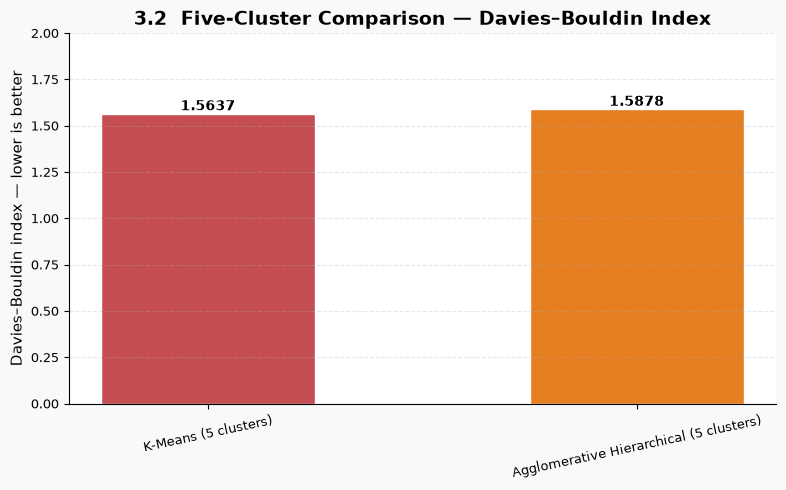

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(clustering["Algorithm"], clustering["Davies-Bouldin"],
              color=[CLUST_COLOUR, "#E67E22"], edgecolor="white", width=0.5)
ax.set_ylabel("Davies–Bouldin index — lower is better")
ax.set_title("3.2  Five-Cluster Comparison — Davies–Bouldin Index")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_ylim(0, 2.0)
for b, v in zip(bars, clustering["Davies-Bouldin"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02,
            f"{v:.4f}", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

---
### 3.3 Calinski–Harabasz score — K-Means vs Agglomerative

**What it means:** This score compares between-cluster dispersion with within-cluster dispersion. **Higher is better.**

**Interpretation:** K-Means has the higher score (**2511.51** vs 2356.56), so it performs better according to this metric.

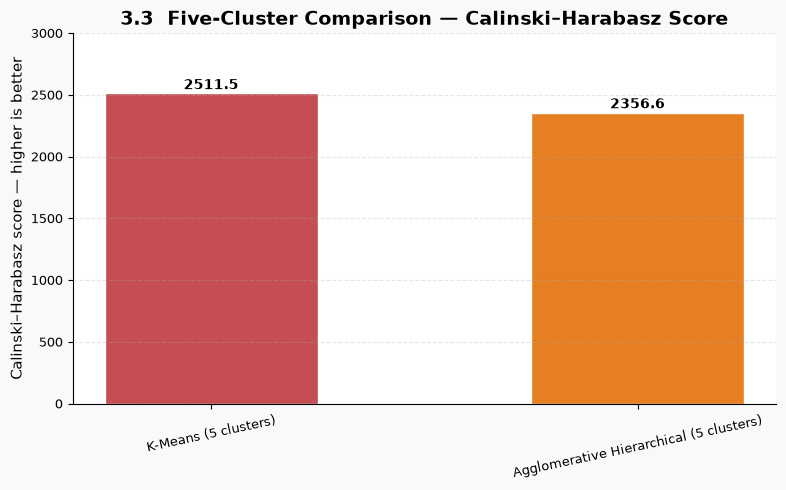

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(clustering["Algorithm"], clustering["Calinski-Harabasz"],
              color=[CLUST_COLOUR, "#E67E22"], edgecolor="white", width=0.5)
ax.set_ylabel("Calinski–Harabasz score — higher is better")
ax.set_title("3.3  Five-Cluster Comparison — Calinski–Harabasz Score")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_ylim(0, 3000)
for b, v in zip(bars, clustering["Calinski-Harabasz"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 35,
            f"{v:.1f}", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

---
### Why clustering metrics can disagree

Agglomerative is **better by silhouette**, while K-Means is **better by Davies–Bouldin and Calinski–Harabasz**. These metrics measure related but different properties, so do not claim one algorithm is the universal winner based on only one metric. Also consider whether the resulting groups are meaningful for the civil-case dataset.

In [26]:
k_results = pd.DataFrame({
    "k":                    [2, 3, 4, 5, 6, 7, 8],
    "Silhouette":           [0.216420, 0.226573, 0.206769, 0.183668,
                             0.180020, 0.184164, 0.187229],
    "Calinski-Harabasz":    [652.995921, 524.027500, 504.533972, 486.936599,
                             475.726709, 463.947652, 445.137428],
    "Davies-Bouldin":       [1.832787, 1.520255, 1.615007, 1.560616,
                             1.562690, 1.655181, 1.616468],
    "Fit time (seconds)":   [2.096065, 3.995562, 4.625053, 5.448004,
                             6.657344, 6.233831, 5.516952]
})

k_results.style \
    .set_caption("K-Means: k = 2 through 8") \
    .format({
        "Silhouette": "{:.6f}",
        "Calinski-Harabasz": "{:.6f}",
        "Davies-Bouldin": "{:.6f}",
        "Fit time (seconds)": "{:.6f}"
    }) \
    .background_gradient(subset=["Silhouette"], cmap="Greens") \
    .set_properties(**{"text-align": "center"})

,k,Silhouette,Calinski-Harabasz,Davies-Bouldin,Fit time (seconds)
0,2,0.216420,652.995921,1.832787,2.096065
1,3,0.226573,524.027500,1.520255,3.995562
2,4,0.206769,504.533972,1.615007,4.625053
3,5,0.183668,486.936599,1.560616,5.448004
4,6,0.180020,475.726709,1.562690,6.657344
5,7,0.184164,463.947652,1.655181,6.233831
6,8,0.187229,445.137428,1.616468,5.516952


---
### 3.4 K-Means silhouette score for k = 2 to 8

**What it means:** This graph compares silhouette scores for different numbers of clusters. If silhouette is the selection criterion, choose the tested *k* with the highest score.

**Interpretation:** *k* = **3** has the highest recorded silhouette score (**0.2266**) among the tested values.

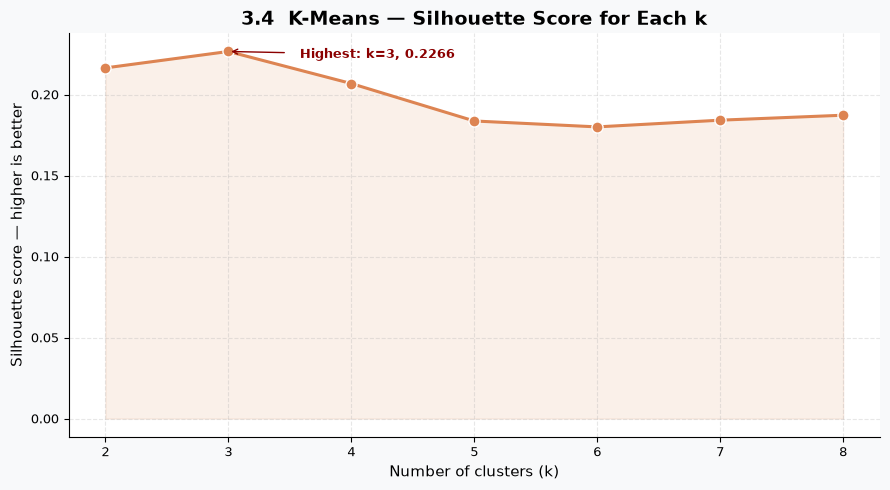

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_results["k"], k_results["Silhouette"],
        marker="o", color=LINE_COLOUR, linewidth=2.2, markersize=8, markeredgecolor="white")
ax.fill_between(k_results["k"], k_results["Silhouette"], alpha=0.12, color=LINE_COLOUR)
ax.set_xticks(k_results["k"])
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score — higher is better")
ax.set_title("3.4  K-Means — Silhouette Score for Each k")
ax.grid(True, linestyle="--", alpha=0.3)
best = k_results.loc[k_results["Silhouette"].idxmax()]
ax.annotate(
    f"  Highest: k={int(best['k'])}, {best['Silhouette']:.4f}",
    xy=(best['k'], best['Silhouette']),
    xytext=(best['k'] + 0.5, best['Silhouette'] - 0.004),
    fontsize=9, color="darkred", fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="darkred")
)
plt.tight_layout()
plt.show()

---
### 3.5 K-Means Davies–Bouldin index for k = 2 to 8

**What it means:** **Lower values** are preferred. This metric may select a different *k* than silhouette, because it evaluates clusters differently.

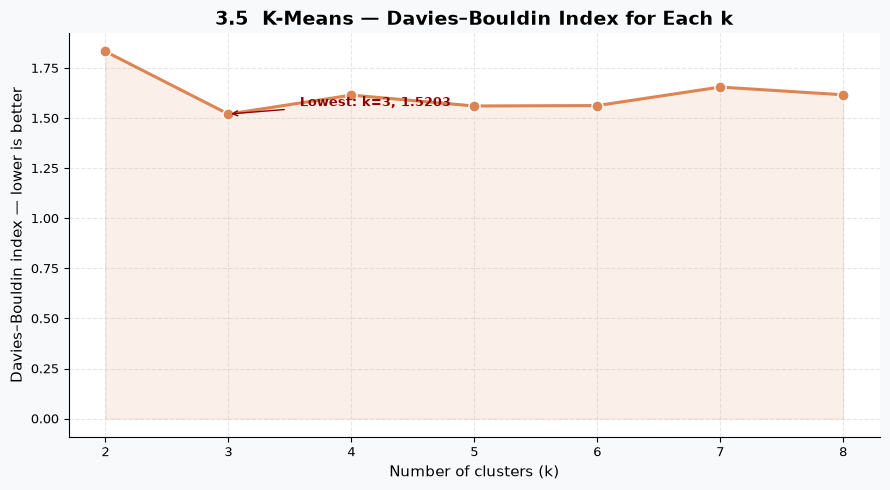

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_results["k"], k_results["Davies-Bouldin"],
        marker="o", color=LINE_COLOUR, linewidth=2.2, markersize=8, markeredgecolor="white")
ax.fill_between(k_results["k"], k_results["Davies-Bouldin"], alpha=0.12, color=LINE_COLOUR)
ax.set_xticks(k_results["k"])
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Davies–Bouldin index — lower is better")
ax.set_title("3.5  K-Means — Davies–Bouldin Index for Each k")
ax.grid(True, linestyle="--", alpha=0.3)
best = k_results.loc[k_results["Davies-Bouldin"].idxmin()]
ax.annotate(
    f"  Lowest: k={int(best['k'])}, {best['Davies-Bouldin']:.4f}",
    xy=(best['k'], best['Davies-Bouldin']),
    xytext=(best['k'] + 0.5, best['Davies-Bouldin'] + 0.04),
    fontsize=9, color="darkred", fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="darkred")
)
plt.tight_layout()
plt.show()

---
### 3.6 K-Means Calinski–Harabasz score for k = 2 to 8

**What it means:** **Higher values** are preferred. A higher score suggests stronger separation relative to within-cluster dispersion.

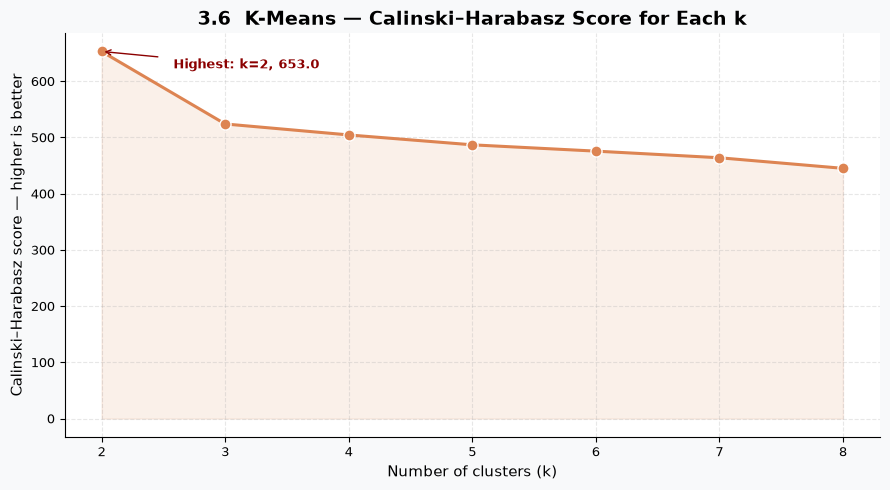

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_results["k"], k_results["Calinski-Harabasz"],
        marker="o", color=LINE_COLOUR, linewidth=2.2, markersize=8, markeredgecolor="white")
ax.fill_between(k_results["k"], k_results["Calinski-Harabasz"], alpha=0.12, color=LINE_COLOUR)
ax.set_xticks(k_results["k"])
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Calinski–Harabasz score — higher is better")
ax.set_title("3.6  K-Means — Calinski–Harabasz Score for Each k")
ax.grid(True, linestyle="--", alpha=0.3)
best = k_results.loc[k_results["Calinski-Harabasz"].idxmax()]
ax.annotate(
    f"  Highest: k={int(best['k'])}, {best['Calinski-Harabasz']:.1f}",
    xy=(best['k'], best['Calinski-Harabasz']),
    xytext=(best['k'] + 0.5, best['Calinski-Harabasz'] - 30),
    fontsize=9, color="darkred", fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="darkred")
)
plt.tight_layout()
plt.show()

---
### 3.7 K-Means fitting time for k = 2 to 8

**What it means:** This compares recorded fitting times for the tested cluster counts. **Lower is faster.** Fit time is not a clustering-quality metric.

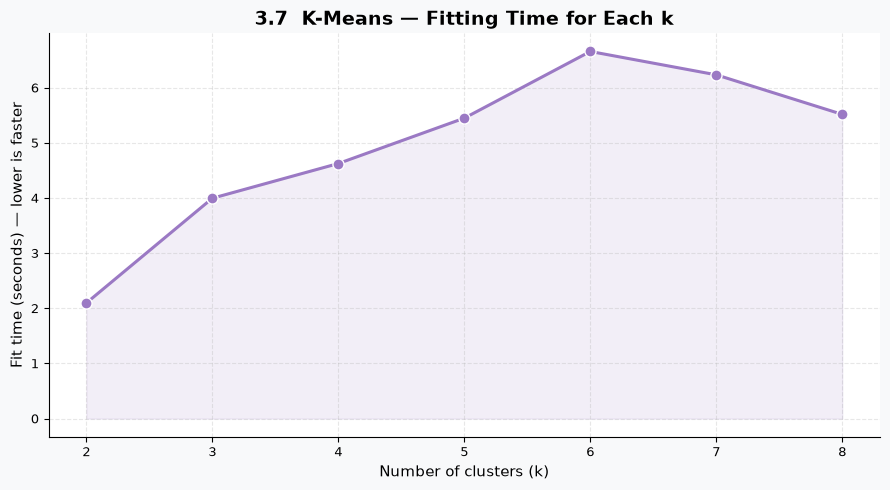

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_results["k"], k_results["Fit time (seconds)"],
        marker="o", color="#9b79c4", linewidth=2.2, markersize=8, markeredgecolor="white")
ax.fill_between(k_results["k"], k_results["Fit time (seconds)"], alpha=0.12, color="#9b79c4")
ax.set_xticks(k_results["k"])
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Fit time (seconds) — lower is faster")
ax.set_title("3.7  K-Means — Fitting Time for Each k")
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

---
### Clustering summary

| Metric | Better algorithm | Notes |
|--------|----------------|-------|
| Silhouette (5 clusters) | **Agglomerative** (0.2098) | Higher is better |
| Davies–Bouldin (5 clusters) | **K-Means** (1.5637) | Lower is better |
| Calinski–Harabasz (5 clusters) | **K-Means** (2511.51) | Higher is better |

- **K-Means *k* comparison:** *k* = **3** has the highest silhouette score (0.2266) among *k* = 2…8.

> This *k*-selection result is from a **separate experiment** and must not be presented as the same run as the fixed five-cluster comparison.

---
## Final Presentation Summary

| Task | Main takeaway |
|------|---------------|
| **Classification** | MLP leads by baseline accuracy and weighted F1; Random Forest leads by weighted precision and ROC-AUC. |
| **Regression** | Random Forest leads the baseline R², RMSE and MAE comparisons; tuning modestly improves R². |
| **Clustering** | The fixed five-cluster metrics disagree; K-Means with *k* = 3 has the best silhouette among tested *k* values. |

---

### Suggested closing script

*“Our comparison evaluates each model using separate graphs for each metric, so we compare like with like. For classification, MLP has the strongest baseline accuracy and weighted F1, while Random Forest has the highest ROC-AUC. For regression, Random Forest gives the strongest baseline R² and the lowest error measures, and tuning improves its R² modestly. For clustering, different internal metrics favour different algorithms, while the separate K-Means experiment achieves its highest silhouette score at three clusters.”*

---

### Data provenance note

The comparison values are copied from saved outputs in the project's original notebooks (`classification.ipynb`, `regression.ipynb`, `clustering.ipynb`). Precision and recall values are weighted averages as recorded by the classification evaluation code.  
**If you retrain the models and the metrics change, update the tables here before presenting.**